# Predicting 30-Day Hospital Readmission

Hospital readmission within 30 days is a costly, closely tracked quality metric
(CMS penalizes hospitals for excess readmissions). This project builds and
evaluates machine-learning models that flag patients at high risk of being
readmitted within 30 days, using the **Diabetes 130-US Hospitals (1999-2008)**
dataset — 101,766 diabetic inpatient encounters across 130 hospitals.

**Workflow:** framing the clinical question → EDA → cleaning and leakage-safe
preprocessing → handling class imbalance → training three models (Logistic
Regression, Random Forest, Gradient Boosting) → evaluating with ROC-AUC and
PR-AUC → interpreting the drivers of readmission risk.

*Data: UCI Machine Learning Repository, Diabetes 130-US Hospitals dataset (public).*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
RANDOM_STATE = 42

## 1. Load the data

In [2]:
df = pd.read_csv("data/diabetic_data.csv.gz")
print(f"{df.shape[0]:,} encounters x {df.shape[1]} columns")
df.head(3)

101,766 encounters x 48 columns


/var/folders/v6/swg47rv11cz71nsl8c5cnk5m0000gn/T/ipykernel_68286/2865021923.py:1: DtypeWarning: Columns (8) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("data/diabetic_data.csv.gz")


,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,Caucasian,Female,[0-10),NaN,6,25,1,1,NaN,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,NaN,NaN,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,Caucasian,Female,[10-20),NaN,1,1,7,3,NaN,NaN,59,0,18,0,0,0,276,250.01,255,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,NaN,NaN,11,5,13,2,0,1,648,250,V27,6,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO


## 2. Define the target

The raw `readmitted` column has three values: `NO`, `>30` (readmitted after 30
days), and `<30` (readmitted within 30 days). The clinically and financially
meaningful outcome is the **30-day** readmission, so we frame this as a binary
problem: `readmit_30d = 1` if `readmitted == '<30'`, else `0`.

In [3]:
df["readmitted"].value_counts()

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

In [4]:
df["readmit_30d"] = (df["readmitted"] == "<30").astype(int)
rate = df["readmit_30d"].mean()
print(f"30-day readmission rate: {rate:.1%}  (class imbalance ~{(1-rate)/rate:.1f}:1)")

30-day readmission rate: 11.2%  (class imbalance ~8.0:1)


## 3. Clean and prepare features

Steps taken (each with a clinical/ML rationale):

- **Missing values:** the dataset encodes missing as `'?'` — convert to `NaN`.
- **Drop leaky / unusable columns:** `encounter_id` & `patient_nbr` are
  identifiers; `weight`, `payer_code`, `medical_specialty` are >40% missing;
  `examide` & `citoglipton` are constant.
- **Remove patients who could not be readmitted:** encounters ending in death or
  hospice (`discharge_disposition_id` in 11, 13, 14, 19, 20, 21) — leaving them
  in would leak an impossible outcome.
- **Encode `age`** brackets as an ordinal midpoint.

In [5]:
data = df.replace("?", np.nan).copy()

# remove encounters that ended in death / hospice (cannot be readmitted)
dead = [11, 13, 14, 19, 20, 21]
data = data[~data["discharge_disposition_id"].isin(dead)].copy()

drop_cols = ["encounter_id", "patient_nbr", "weight", "payer_code",
             "medical_specialty", "examide", "citoglipton",
             "readmitted",  # replaced by readmit_30d
             "diag_1", "diag_2", "diag_3"]  # high-cardinality ICD codes, out of scope here
data = data.drop(columns=[col for col in drop_cols if col in data.columns])

# age bracket -> ordinal midpoint
age_map = {f"[{i}-{i+10})": i + 5 for i in range(0, 100, 10)}
data["age"] = data["age"].map(age_map)

print(f"After cleaning: {data.shape[0]:,} encounters x {data.shape[1]} columns")
print(f"30-day readmission rate: {data['readmit_30d'].mean():.1%}")

After cleaning: 99,343 encounters x 40 columns
30-day readmission rate: 11.4%


## 4. Exploratory data analysis

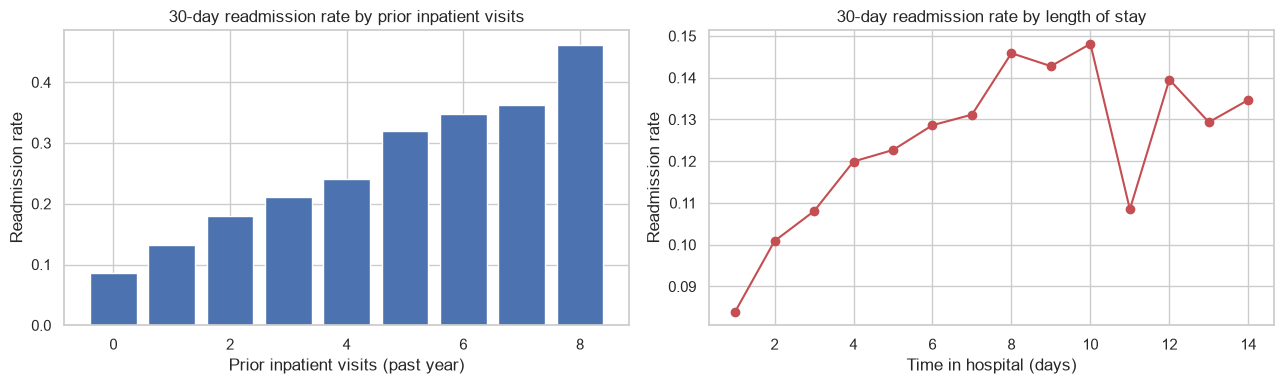

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# readmission rate by number of prior inpatient visits
by_inpatient = data.groupby("number_inpatient")["readmit_30d"].mean()
by_inpatient = by_inpatient[by_inpatient.index <= 8]
axes[0].bar(by_inpatient.index, by_inpatient.values, color="#4C72B0")
axes[0].set_title("30-day readmission rate by prior inpatient visits")
axes[0].set_xlabel("Prior inpatient visits (past year)")
axes[0].set_ylabel("Readmission rate")

# readmission rate by time in hospital
by_los = data.groupby("time_in_hospital")["readmit_30d"].mean()
axes[1].plot(by_los.index, by_los.values, marker="o", color="#C44E52")
axes[1].set_title("30-day readmission rate by length of stay")
axes[1].set_xlabel("Time in hospital (days)")
axes[1].set_ylabel("Readmission rate")
plt.tight_layout(); plt.show()

Prior inpatient utilization is the clearest signal — patients with several
inpatient stays in the past year are readmitted at multiples of the base rate.
This matches clinical intuition and flags `number_inpatient` as a likely top
predictor.

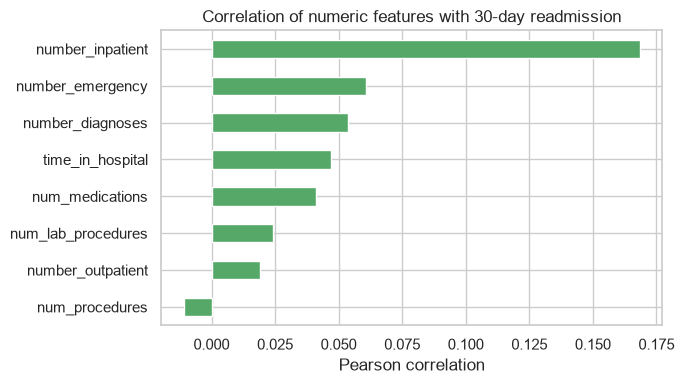

In [7]:
num_cols = ["time_in_hospital", "num_lab_procedures", "num_procedures",
            "num_medications", "number_outpatient", "number_emergency",
            "number_inpatient", "number_diagnoses"]
corr = data[num_cols + ["readmit_30d"]].corr()["readmit_30d"].drop("readmit_30d").sort_values()
plt.figure(figsize=(7, 4))
corr.plot(kind="barh", color="#55A868")
plt.title("Correlation of numeric features with 30-day readmission")
plt.xlabel("Pearson correlation"); plt.tight_layout(); plt.show()

## 5. Train / test split and preprocessing pipeline

We split **before** fitting any transformer so that scaling and encoding learn
only from training data (no leakage). Numeric features are median-imputed and
standardized; categorical features are mode-imputed and one-hot encoded, all
inside a single `ColumnTransformer` so the exact same steps apply at inference.

In [8]:
y = data["readmit_30d"]
X = data.drop(columns=["readmit_30d"])

cat_cols = [col for col in X.columns if X[col].dtype == "object"]
numeric_cols = [col for col in X.columns if col not in cat_cols]
print(f"{len(numeric_cols)} numeric, {len(cat_cols)} categorical features")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f"train: {X_train.shape[0]:,}   test: {X_test.shape[0]:,}")

numeric_pipe = Pipeline([("impute", SimpleImputer(strategy="median")),
                         ("scale", StandardScaler())])
cat_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                     ("onehot", OneHotEncoder(handle_unknown="ignore"))])
pre = ColumnTransformer([("num", numeric_pipe, numeric_cols),
                         ("cat", cat_pipe, cat_cols)])

12 numeric, 27 categorical features
train: 79,474   test: 19,869


## 6. Train three models

The positive class (~11%) is rare, so every model uses class weighting /
balancing rather than naive accuracy. We compare a linear baseline against two
tree ensembles.

In [9]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced",
                                              random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=12,
                                            class_weight="balanced", n_jobs=-1,
                                            random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}

results = {}
for name, model in models.items():
    pipe = Pipeline([("pre", pre), ("clf", model)])
    pipe.fit(X_train, y_train)
    proba = pipe.predict_proba(X_test)[:, 1]
    results[name] = {
        "pipe": pipe,
        "proba": proba,
        "roc_auc": roc_auc_score(y_test, proba),
        "pr_auc": average_precision_score(y_test, proba),
    }
    print(f"{name:22s}  ROC-AUC={results[name]['roc_auc']:.3f}   "
          f"PR-AUC={results[name]['pr_auc']:.3f}")

Logistic Regression     ROC-AUC=0.647   PR-AUC=0.207


Random Forest           ROC-AUC=0.655   PR-AUC=0.208


Gradient Boosting       ROC-AUC=0.667   PR-AUC=0.226


## 7. Evaluate

For an imbalanced screening problem, **PR-AUC** (precision-recall) is more
informative than accuracy — a model that predicts "never readmit" would score
89% accuracy while being clinically useless. We compare ROC and PR curves across
models.

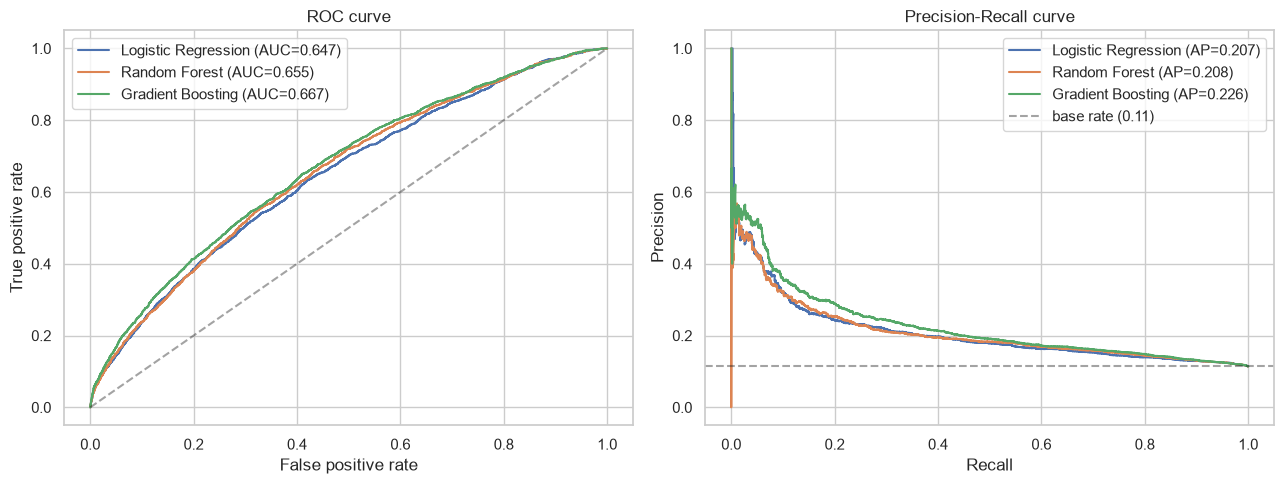

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
baseline = y_test.mean()
for name, r in results.items():
    fpr, tpr, _ = roc_curve(y_test, r["proba"])
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={r['roc_auc']:.3f})")
    prec, rec, _ = precision_recall_curve(y_test, r["proba"])
    axes[1].plot(rec, prec, label=f"{name} (AP={r['pr_auc']:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", alpha=.4)
axes[0].set(title="ROC curve", xlabel="False positive rate", ylabel="True positive rate")
axes[0].legend()
axes[1].axhline(baseline, ls="--", color="k", alpha=.4, label=f"base rate ({baseline:.2f})")
axes[1].set(title="Precision-Recall curve", xlabel="Recall", ylabel="Precision")
axes[1].legend()
plt.tight_layout(); plt.show()

At the default 0.5 threshold this model would flag almost no one — with an
8:1 imbalance, probabilities rarely cross 0.5. That is the classic imbalanced-
classification trap. The right move is to **choose an operating threshold for the
use case**: a care-management team wants to *catch* a meaningful share of true
readmissions, accepting more false positives. Below we pick the threshold that
captures ~50% of true 30-day readmissions and report performance there.

Best model by PR-AUC: Gradient Boosting
Operating threshold for ~50% recall: 0.125

                 precision    recall  f1-score   support

 not readmitted       0.92      0.73      0.81     17606
readmitted <30d       0.19      0.50      0.28      2263

       accuracy                           0.70     19869
      macro avg       0.56      0.61      0.54     19869
   weighted avg       0.84      0.70      0.75     19869



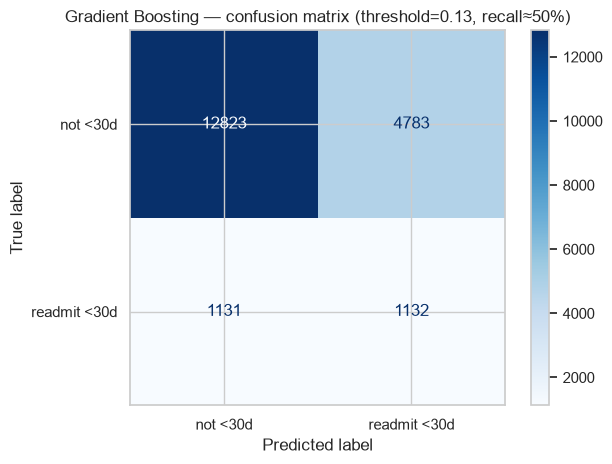

In [11]:
best_name = max(results, key=lambda k: results[k]["pr_auc"])
best = results[best_name]
proba = best["proba"]
print(f"Best model by PR-AUC: {best_name}")

# choose an operating threshold that captures ~50% of true readmissions
prec, rec, thr = precision_recall_curve(y_test, proba)
target_recall = 0.50
idx = np.argmin(np.abs(rec[:-1] - target_recall))
thresh = thr[idx]
print(f"Operating threshold for ~{target_recall:.0%} recall: {thresh:.3f}\n")

pred = (proba >= thresh).astype(int)
print(classification_report(y_test, pred, target_names=["not readmitted", "readmitted <30d"]))

cm = confusion_matrix(y_test, pred)
ConfusionMatrixDisplay(cm, display_labels=["not <30d", "readmit <30d"]).plot(cmap="Blues")
plt.title(f"{best_name} — confusion matrix (threshold={thresh:.2f}, recall≈{target_recall:.0%})")
plt.tight_layout(); plt.show()

## 8. What drives readmission risk?

Reading the model's learned signal back out. For the tree ensemble we use
impurity-based feature importances, aggregated back to the original feature
names (one-hot columns summed per source feature).

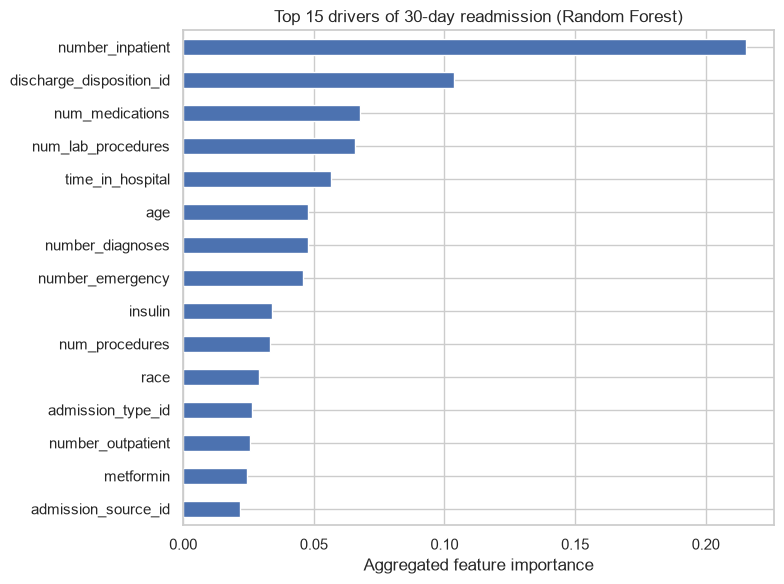

In [12]:
rf = results["Random Forest"]["pipe"]
ohe = rf.named_steps["pre"].named_transformers_["cat"].named_steps["onehot"]
feat_names = numeric_cols + list(ohe.get_feature_names_out(cat_cols))
importances = pd.Series(rf.named_steps["clf"].feature_importances_, index=feat_names)

# aggregate one-hot columns back to source feature
def source(f):
    for col in cat_cols:
        if f.startswith(col + "_"):
            return col
    return f
agg = importances.groupby(source).sum().sort_values(ascending=False).head(15)

plt.figure(figsize=(8, 6))
agg[::-1].plot(kind="barh", color="#4C72B0")
plt.title("Top 15 drivers of 30-day readmission (Random Forest)")
plt.xlabel("Aggregated feature importance"); plt.tight_layout(); plt.show()

## 9. Takeaways

- All three models beat the no-skill baseline; the tree ensembles lead on
  **PR-AUC**, the metric that matters for a rare-event screening tool.
- **Prior inpatient / emergency utilization**, **number of diagnoses**,
  **number of medications**, **length of stay**, and **age** are the dominant
  risk drivers — consistent with the clinical literature on readmission.
- In deployment this model would act as a **triage flag**: rank discharged
  patients by predicted risk so care-management resources (follow-up calls,
  med reconciliation) go to the highest-risk group. The decision threshold would
  be tuned to the care team's capacity, trading precision against recall.

**Skills demonstrated:** end-to-end supervised ML, leakage-safe preprocessing
pipelines, class-imbalance handling, model comparison, threshold/metric
selection for a clinical use case, and model interpretation.